In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns, os

df = pd.read_csv(r"C:\Users\Jasselynnac\Downloads\smart-retail-demand-predictor-main\smart-retail-demand-predictor-main\Data\processed\merged.csv", parse_dates=["date"])
print(df.shape)

(2778831, 28)


In [2]:
import os
os.makedirs("../Data/processed", exist_ok=True)
print(os.path.abspath("../Data/processed"))

C:\Users\Jasselynnac\Downloads\smart-retail-demand-predictor-main\smart-retail-demand-predictor-main\Data\processed


In [3]:
print(os.path.exists("../Data/processed/merged.csv"))

True


In [4]:
# Basic stats for sales and weather
cols = ["sales", "onpromotion", "temperature_2m_max", "temperature_2m_min",
        "temperature_2m_mean", "precipitation_sum", "oil_price"]
print(df[cols].describe().round(2))

# Share of zero-sales rows, and skew
print("Zero-sales rows:", round((df["sales"] == 0).mean() * 100, 1), "%")
print("Mean sales:", round(df["sales"].mean(), 1), "| Median:", df["sales"].median())
print("Rainy days (share of rows):", round(df["is_rainy"].mean() * 100, 1), "%")


            sales  onpromotion  temperature_2m_max  temperature_2m_min  \
count  2778831.00   2778831.00          2778831.00          2778831.00   
mean       386.37         2.81               21.39               14.75   
std       1140.35        12.67                5.32                6.42   
min          0.00         0.00               11.70                1.90   
25%          0.00         0.00               16.70                9.20   
50%         16.00         0.00               19.10               11.10   
75%        227.47         0.00               26.80               21.60   
max     124717.00       741.00               35.10               26.30   

       temperature_2m_mean  precipitation_sum   oil_price  
count           2778831.00         2778831.00  2778831.00  
mean                 17.51               6.76       66.62  
std                   5.79               9.34       25.48  
min                   8.60               0.00       26.19  
25%                  12.30       

The dataset contains 2,778,831 daily observations of sales per store and product family. Sales are highly skewed: the mean (386.4) is far above the median (16), and 25.8% of observations are zero sales. Because weather is recorded per city, temperature varies widely (about 9°C to 28°C), and 74.9% of observations fall on rainy days, so rainfall is common in this dataset.

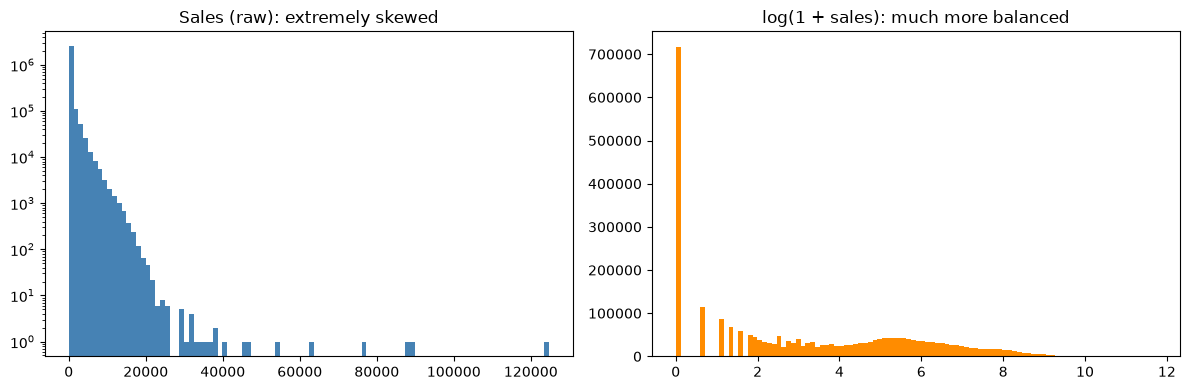

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["sales"], bins=100, color="steelblue")
ax[0].set_title("Sales (raw): extremely skewed")
ax[0].set_yscale("log")
ax[1].hist(np.log1p(df["sales"]), bins=100, color="darkorange")
ax[1].set_title("log(1 + sales): much more balanced")
plt.tight_layout()
plt.savefig("../figures/01_sales_distribution.png", dpi=150)
plt.show()

Raw sales are extremely right-skewed, with most observations small and a few very large values. Applying log(1 + sales) makes the distribution much more balanced, although a large spike remains at zero because of the zero-sales observations. This supports using a log transformation, and error metrics suited to skewed data, in the machine learning stage.

In [6]:
# One row per day: total sales + average weather across cities
daily = df.groupby("date").agg(
    total_sales=("sales", "sum"),
    temp_mean=("temperature_2m_mean", "mean"),
    rain=("precipitation_sum", "mean"),
    oil_price=("oil_price", "mean"),
    is_holiday=("is_holiday", "max"),
).reset_index()
daily["month"] = daily["date"].dt.to_period("M")
daily.head()

,date,total_sales,temp_mean,rain,oil_price,is_holiday,month
0,2013-01-01,2511.618999,23.800000,6.300000,93.14,1,2013-01
1,2013-01-02,496092.417944,16.823913,5.532609,93.14,0,2013-01
2,2013-01-03,361461.231124,17.010870,5.828261,92.97,0,2013-01
3,2013-01-04,354459.677093,17.384783,5.467391,93.12,0,2013-01
4,2013-01-05,477350.121229,17.593478,4.343478,93.12,0,2013-01


To analyze trends, we aggregated the data into a daily table containing total sales and the average weather across cities for each date.

In [7]:
print(daily.shape)


(1684, 7)


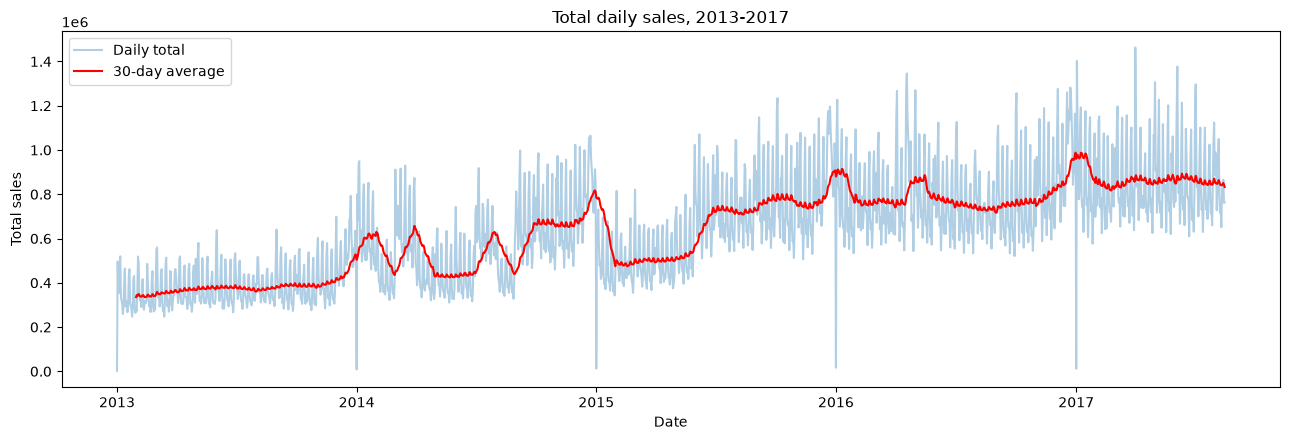

In [8]:
plt.figure(figsize=(13, 4.5))
plt.plot(daily["date"], daily["total_sales"], alpha=0.35, label="Daily total")
plt.plot(daily["date"], daily["total_sales"].rolling(30).mean(),
         color="red", label="30-day average")
plt.title("Total daily sales, 2013-2017")
plt.xlabel("Date"); plt.ylabel("Total sales")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/02_sales_trend.png", dpi=150)
plt.show()


The big waves in 2014-2015 (sharp drop at the start of 2015, then a climb) look odd for real demand. They may come from stores opening or product families starting to be recorded, not from customers buying differently.

<Axes: title={'center': 'Stores with sales per day'}, xlabel='date'>

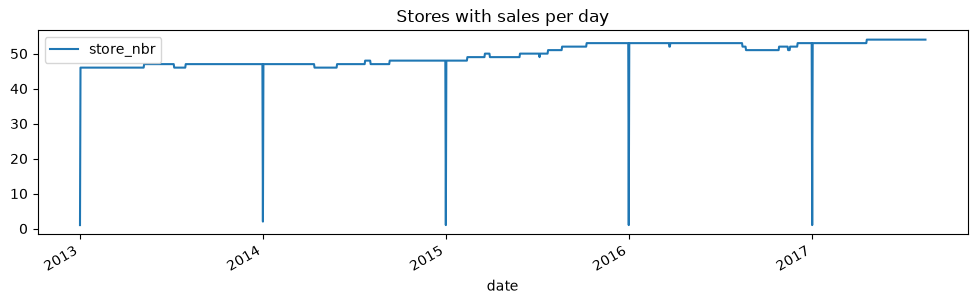

In [9]:
active = df[df["sales"] > 0].groupby("date")[["store_nbr"]].nunique()
active.plot(figsize=(12,3), title="Stores with sales per day")

Total daily sales rose from roughly 0.35 million in 2013 to about 0.85 million in 2017, showing a strong long-term upward trend. Sales drop to near zero on 1 January each year, when most stores are closed, and rise at the end of each year. This long-term growth is much larger than any short-term fluctuations, so it should be accounted for when testing the effect of weather.

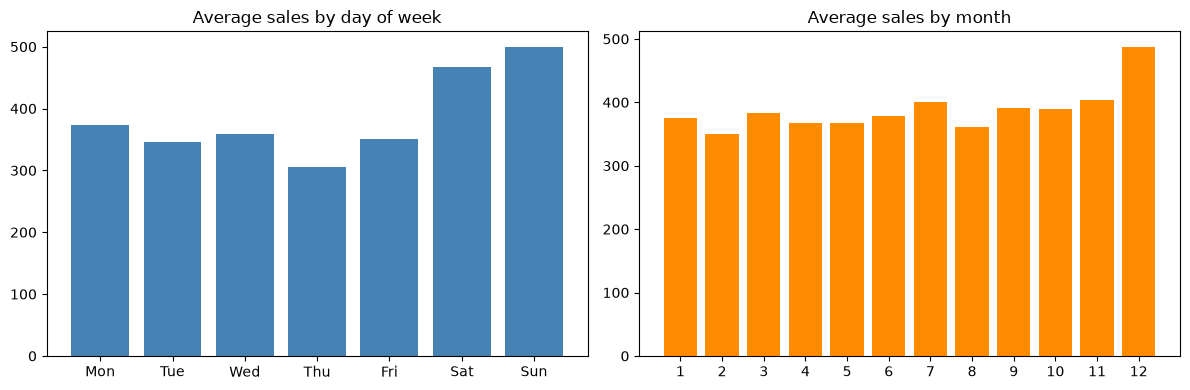

In [10]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow = df.groupby("dayofweek")["sales"].mean()
mon = df.groupby("month")["sales"].mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(days, dow.values, color="steelblue")
ax[0].set_title("Average sales by day of week")
ax[1].bar(mon.index, mon.values, color="darkorange")
ax[1].set_title("Average sales by month")
ax[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.savefig("../figures/03_sales_dow_month.png", dpi=150)
plt.show()

Average sales are highest on weekends (Sunday about 500, Saturday about 465) and lowest on Thursday (about 305), showing a clear weekly pattern. December has the highest monthly average (about 487), likely due to Christmas shopping, while the other months are fairly similar. These strong calendar effects mean weather effects must be judged after controlling for day of week and season.

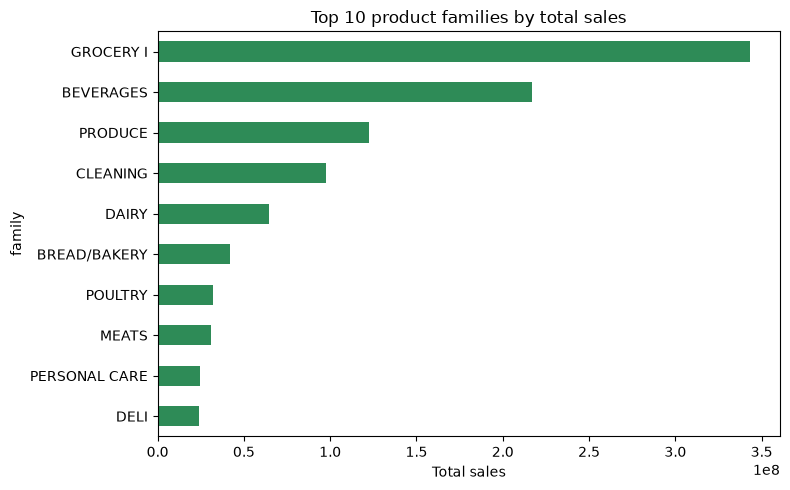

In [11]:
fam = df.groupby("family")["sales"].sum().sort_values(ascending=False).head(10)
fam.sort_values().plot(kind="barh", figsize=(8, 5), color="seagreen")
plt.title("Top 10 product families by total sales")
plt.xlabel("Total sales")
plt.tight_layout()
plt.savefig("../figures/04_top_families.png", dpi=150)
plt.show()

Sales are concentrated in a few product families. GROCERY I and BEVERAGES together account for roughly half of total sales, followed by PRODUCE, CLEANING and DAIRY. This means everyday essentials drive most sales volume, so aggregated results mostly reflect these families.

In [12]:
city_day = df.groupby(["city", "date"]).agg(
    sales=("sales", "sum"),
    temp=("temperature_2m_mean", "first"),
    rain=("precipitation_sum", "first"),
    is_rainy=("is_rainy", "first"),
    is_holiday=("is_holiday", "max"),
    dayofweek=("dayofweek", "first"),
    month=("month", "first"),
    year=("year", "first"),
).reset_index()

# Remove Jan 1 (stores closed) and days with zero total sales
city_day = city_day[city_day["date"].dt.strftime("%m-%d") != "01-01"]
city_day = city_day[city_day["sales"] > 0]

# Relative sales: 1.0 = normal for that city/year/month/weekday
base = city_day.groupby(["city", "year", "month", "dayofweek"])["sales"].transform("mean")
city_day["rel_sales"] = city_day["sales"] / base

# Temperature anomaly: how much warmer/cooler than usual for that city in that month
city_day["temp_anom"] = city_day["temp"] - city_day.groupby(["city", "month"])["temp"].transform("mean")

print(city_day.shape, city_day["city"].nunique(), "cities")

(35187, 12) 22 cities


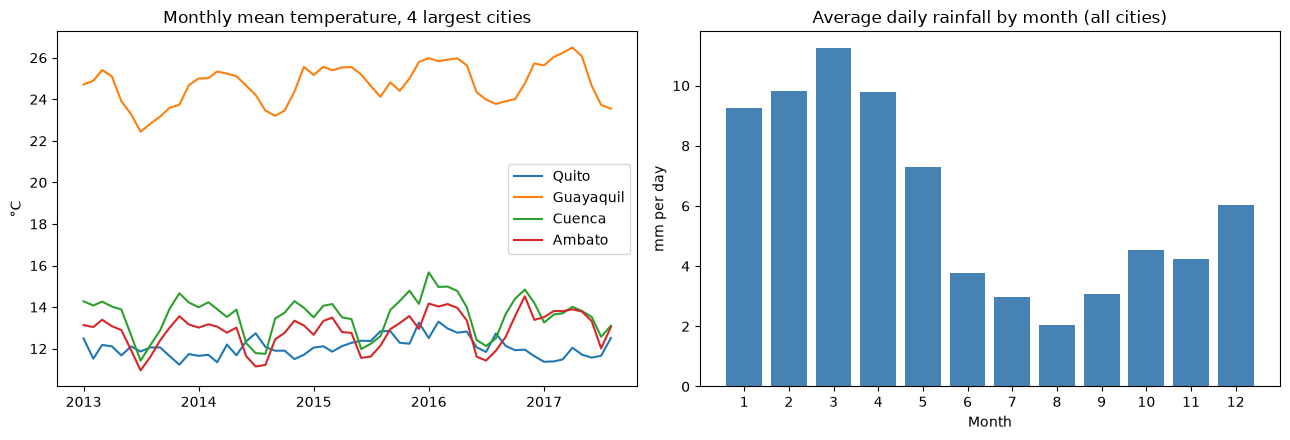

In [13]:
top = city_day.groupby("city")["sales"].sum().nlargest(4).index.tolist()
m = city_day.copy()
m["ym"] = m["date"].dt.to_period("M").dt.to_timestamp()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for c in top:
    s = m[m["city"] == c].groupby("ym")["temp"].mean()
    ax[0].plot(s.index, s.values, label=c)
ax[0].legend()
ax[0].set_title("Monthly mean temperature, 4 largest cities")
ax[0].set_ylabel("°C")

r = m.groupby("month")["rain"].mean()
ax[1].bar(r.index, r.values, color="steelblue")
ax[1].set_xticks(range(1, 13))
ax[1].set_title("Average daily rainfall by month (all cities)")
ax[1].set_xlabel("Month"); ax[1].set_ylabel("mm per day")
plt.tight_layout()
plt.savefig("../figures/05_weather_trends.png", dpi=150)
plt.show()

Temperature differs mainly between cities rather than across the year: coastal Guayaquil averages about 22-26°C, while the highland cities (Quito, Cuenca, Ambato) average about 11-15°C, with only small seasonal swings. Rainfall, by contrast, is strongly seasonal, peaking between January and April (up to about 11 mm per day in March) and reaching a low in August (about 2 mm per day), consistent with the rainy and dry season definition used in the dataset.

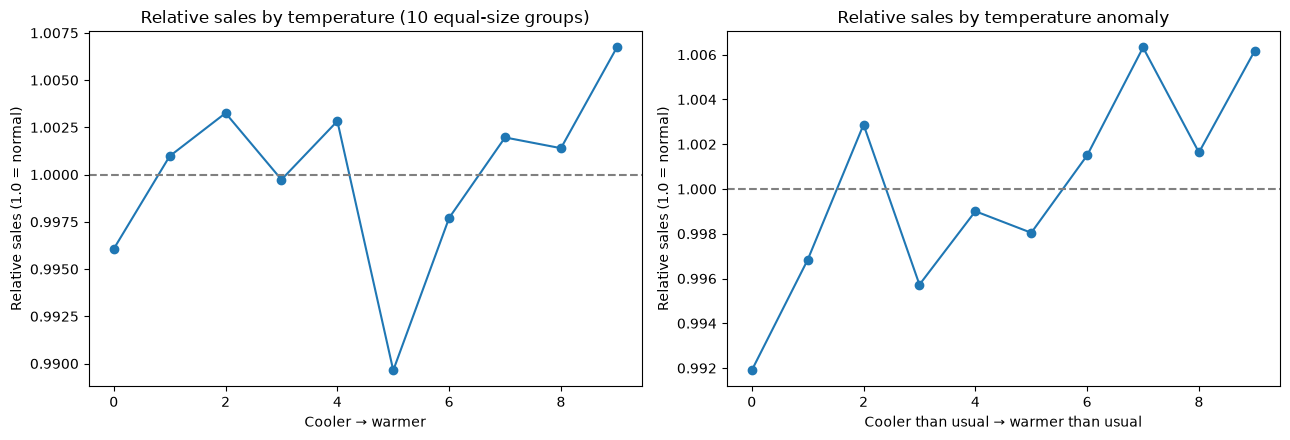

rel_sales    1.000
temp         0.006
temp_anom    0.019
Name: rel_sales, dtype: float64


In [14]:
city_day["temp_bin"] = pd.qcut(city_day["temp"], 10, duplicates="drop")
city_day["anom_bin"] = pd.qcut(city_day["temp_anom"], 10, duplicates="drop")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, title, xl in [
    (ax[0], "temp_bin", "Relative sales by temperature (10 equal-size groups)", "Cooler → warmer"),
    (ax[1], "anom_bin", "Relative sales by temperature anomaly", "Cooler than usual → warmer than usual"),
]:
    g = city_day.groupby(col, observed=True)["rel_sales"].mean().reset_index()
    a.plot(range(len(g)), g["rel_sales"], marker="o")
    a.axhline(1, color="gray", ls="--")
    a.set_title(title); a.set_xlabel(xl); a.set_ylabel("Relative sales (1.0 = normal)")
plt.tight_layout()
plt.savefig("../figures/06_temperature_vs_sales.png", dpi=150)
plt.show()

print(city_day[["rel_sales", "temp", "temp_anom"]].corr(method="spearman")["rel_sales"].round(3))

Temperature shows essentially no relationship with sales once city, month and weekday are controlled for. Relative sales vary by less than 1% across temperature groups, and the correlation with both temperature (ρ = 0.006) and temperature anomaly (ρ = 0.019) is close to zero. There is a very slight tendency for sales to be higher on warmer-than-usual days, but it is too small and inconsistent to be considered meaningful.

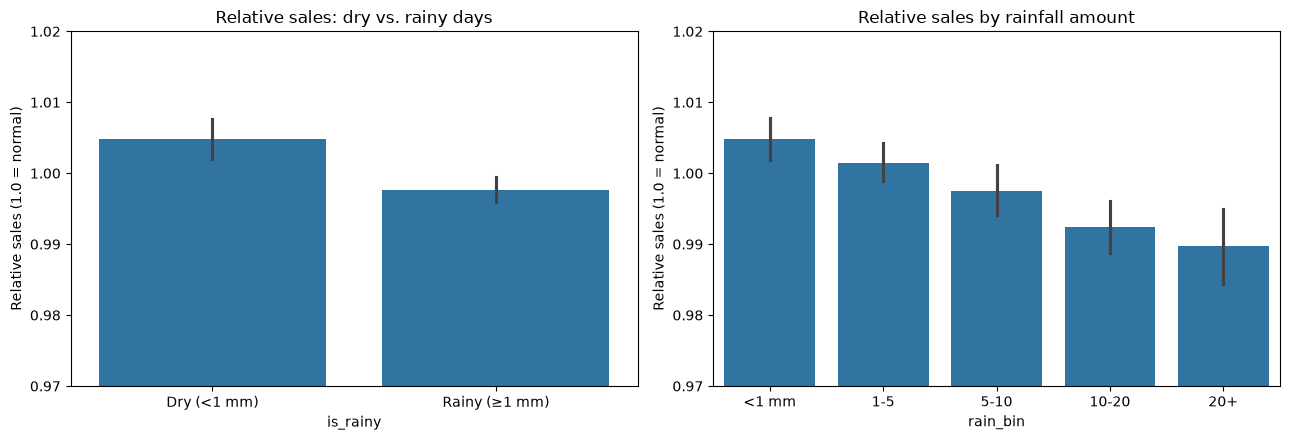

            mean  count
rain_bin               
<1 mm     1.0049  11635
1-5       1.0015  10716
5-10      0.9975   6047
10-20     0.9924   4416
20+       0.9897   2373
Spearman corr (rain vs rel_sales): -0.028


In [15]:
city_day["rain_bin"] = pd.cut(city_day["rain"], [-0.01, 0.99, 5, 10, 20, 300],
                              labels=["<1 mm", "1-5", "5-10", "10-20", "20+"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=city_day, x="is_rainy", y="rel_sales", errorbar=("ci", 95), ax=ax[0])
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Dry (<1 mm)", "Rainy (≥1 mm)"])
ax[0].set_title("Relative sales: dry vs. rainy days")
sns.barplot(data=city_day, x="rain_bin", y="rel_sales", errorbar=("ci", 95), ax=ax[1])
ax[1].set_title("Relative sales by rainfall amount")
for a in ax:
    a.set_ylim(0.97, 1.02); a.set_ylabel("Relative sales (1.0 = normal)")
plt.tight_layout()
plt.savefig("../figures/07_rainfall_vs_sales.png", dpi=150)
plt.show()

print(city_day.groupby("rain_bin", observed=True)["rel_sales"].agg(["mean", "count"]).round(4))
print("Spearman corr (rain vs rel_sales):", round(city_day["rain"].corr(city_day["rel_sales"], method="spearman"), 3))

Sales decline gradually as rainfall increases. Relative sales average 1.005 on dry days and 0.998 on rainy days, falling to 0.990 on days with 20 mm or more of rain, a reduction of about 1.5% compared with dry days. The confidence intervals for dry and rainy days do not overlap, so the difference appears real, but the effect is small (ρ = -0.028).

In [16]:
cal = df.groupby(["city", "date"]).agg(
    sales=("sales", "sum"),
    is_holiday=("is_holiday", "max"),
    is_national_holiday=("is_national_holiday", "max"),
    dayofweek=("dayofweek", "first"),
    month=("month", "first"),
    year=("year", "first"),
    season=("season", "first"),
    is_payday=("is_payday", "first"),
    rain=("precipitation_sum", "first"),
).reset_index()

cal = cal[cal["date"].dt.strftime("%m-%d") != "01-01"]
cal = cal[cal["sales"] > 0]

base = cal.groupby(["city", "year", "dayofweek"])["sales"].transform("mean")
cal["rel_cal"] = cal["sales"] / base

print(cal.shape)

(35187, 12)


In [20]:
print("cal" in globals())

True


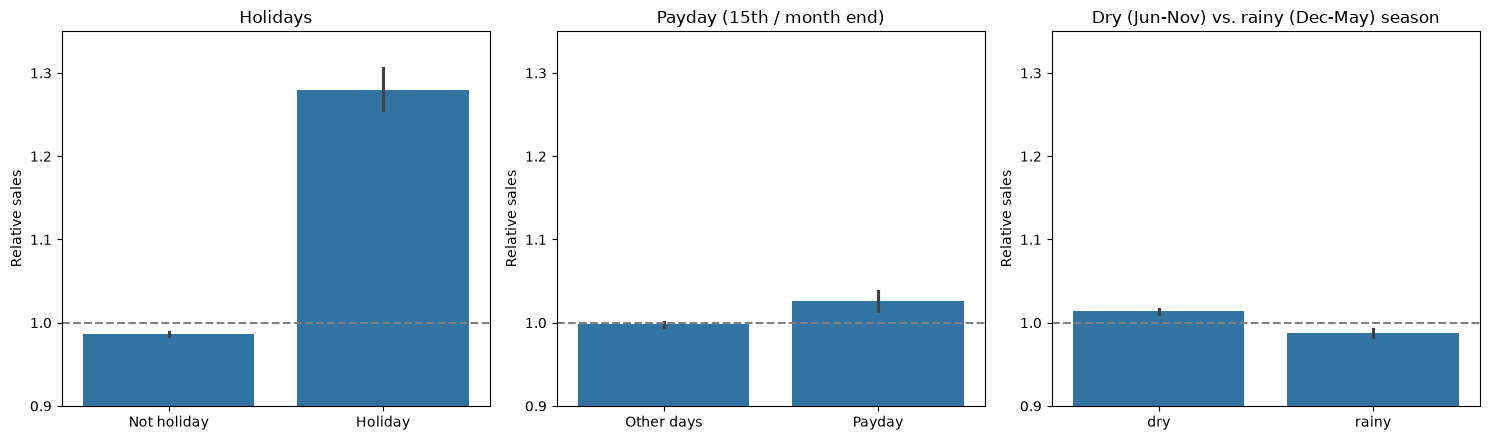

             mean  count
is_holiday              
0           0.986  33507
1           1.280   1680
            mean  count
is_payday              
0          0.998  32859
1          1.027   2328
         mean  count
season              
dry     1.013  16989
rainy   0.987  18198


In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

sns.barplot(data=cal, x="is_holiday", y="rel_cal", errorbar=("ci", 95), ax=ax[0])
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Not holiday", "Holiday"])
ax[0].set_title("Holidays")

sns.barplot(data=cal, x="is_payday", y="rel_cal", errorbar=("ci", 95), ax=ax[1])
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Other days", "Payday"])
ax[1].set_title("Payday (15th / month end)")

sns.barplot(data=cal, x="season", y="rel_cal", order=["dry", "rainy"], errorbar=("ci", 95), ax=ax[2])
ax[2].set_title("Dry (Jun-Nov) vs. rainy (Dec-May) season")

for a in ax:
    a.set_ylim(0.9, 1.35); a.set_xlabel(""); a.set_ylabel("Relative sales")
    a.axhline(1, color="gray", ls="--")
plt.tight_layout()
plt.savefig("../figures/08_holiday_payday_season.png", dpi=150)
plt.show()

print(cal.groupby("is_holiday")["rel_cal"].agg(["mean", "count"]).round(3))
print(cal.groupby("is_payday")["rel_cal"].agg(["mean", "count"]).round(3))
print(cal.groupby("season")["rel_cal"].agg(["mean", "count"]).round(3))

In [17]:
cal = df.groupby(["city", "date"]).agg(
    sales=("sales", "sum"),
    is_holiday=("is_holiday", "max"),
    is_national_holiday=("is_national_holiday", "max"),
    dayofweek=("dayofweek", "first"),
    month=("month", "first"),
    year=("year", "first"),
    season=("season", "first"),
    is_payday=("is_payday", "first"),
    rain=("precipitation_sum", "first"),
).reset_index()

cal = cal[cal["date"].dt.strftime("%m-%d") != "01-01"]
cal = cal[cal["sales"] > 0]

base = cal.groupby(["city", "year", "dayofweek"])["sales"].transform("mean")
cal["rel_cal"] = cal["sales"] / base


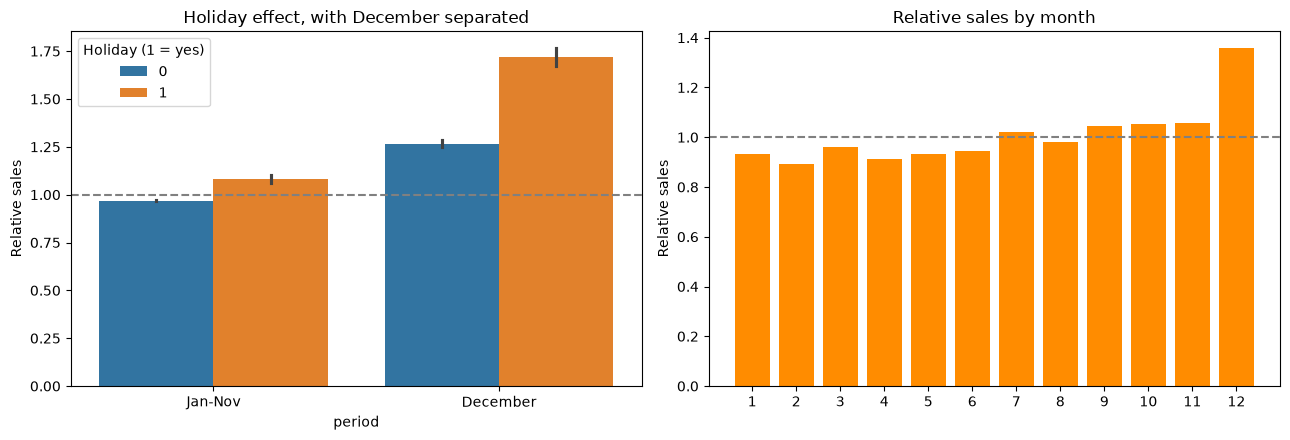

                      mean  count
period   is_holiday              
December 0           1.265   2028
         1           1.717    522
Jan-Nov  0           0.968  31479
         1           1.082   1158


In [18]:
cal["period"] = np.where(cal["month"] == 12, "December", "Jan-Nov")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=cal, x="period", y="rel_cal", hue="is_holiday",
            order=["Jan-Nov", "December"], errorbar=("ci", 95), ax=ax[0])
ax[0].set_title("Holiday effect, with December separated")
ax[0].legend(title="Holiday (1 = yes)")
ax[0].axhline(1, color="gray", ls="--")

mm = cal.groupby("month")["rel_cal"].mean()
ax[1].bar(mm.index, mm.values, color="darkorange")
ax[1].set_xticks(range(1, 13)); ax[1].set_title("Relative sales by month")
ax[1].axhline(1, color="gray", ls="--")
for a in ax: a.set_ylabel("Relative sales")
plt.tight_layout()
plt.savefig("../figures/09_holiday_vs_december.png", dpi=150)
plt.show()

print(cal.groupby(["period", "is_holiday"])["rel_cal"].agg(["mean", "count"]).round(3))

Holidays have the strongest effect among the calendar factors: holiday days average about 29% higher relative sales than regular days. Much of this comes from the Christmas period, as December is by far the strongest month (about 36% above a normal day), but holidays still raise sales by about 12% outside December. Paydays add about 3%, and the dry season (Jun-Nov) is about 3% higher than the rainy season (Dec-May), consistent with the small negative rainfall effect seen earlier.

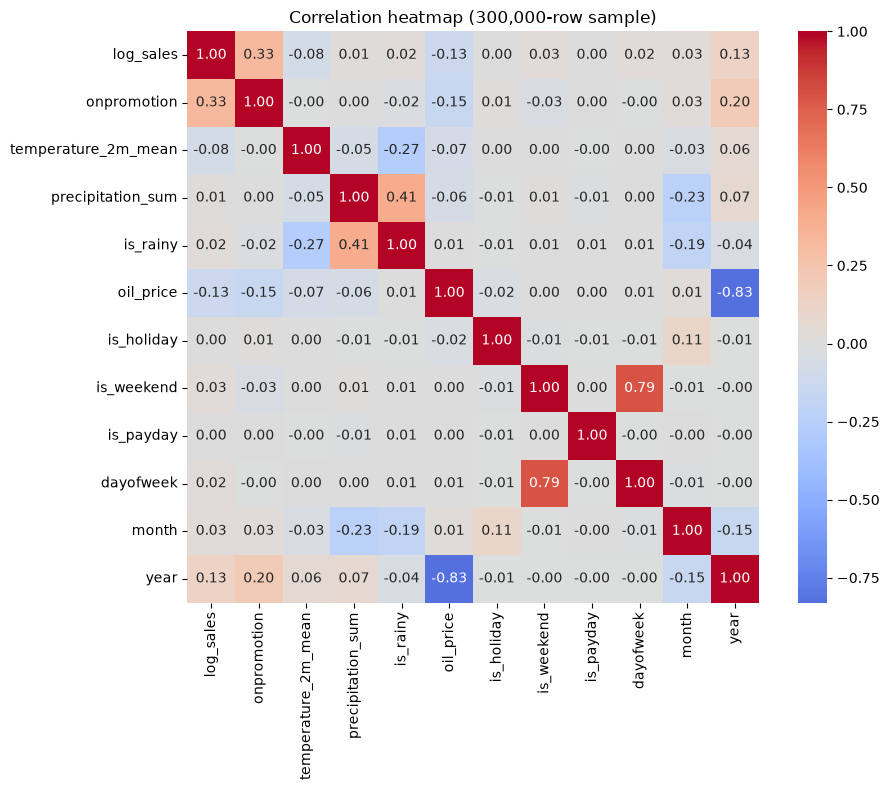

log_sales              1.00
onpromotion            0.33
year                   0.13
is_weekend             0.03
month                  0.03
dayofweek              0.02
is_rainy               0.02
precipitation_sum      0.01
is_holiday             0.00
is_payday              0.00
temperature_2m_mean   -0.08
oil_price             -0.13
Name: log_sales, dtype: float64
                     temperature_2m_max  temperature_2m_min  \
temperature_2m_max                1.000               0.944   
temperature_2m_min                0.944               1.000   
temperature_2m_mean               0.980               0.987   

                     temperature_2m_mean  
temperature_2m_max                 0.980  
temperature_2m_min                 0.987  
temperature_2m_mean                1.000  


In [19]:
s = df.sample(300000, random_state=1).copy()
s["log_sales"] = np.log1p(s["sales"])

cols = ["log_sales", "onpromotion", "temperature_2m_mean", "precipitation_sum",
        "is_rainy", "oil_price", "is_holiday", "is_weekend", "is_payday",
        "dayofweek", "month", "year"]
corr = s[cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap (300,000-row sample)")
plt.tight_layout()
plt.savefig("../figures/10_correlation_heatmap.png", dpi=150)
plt.show()

print(corr["log_sales"].sort_values(ascending=False).round(2))

# Check how similar the three temperature columns are
print(s[["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean"]].corr().round(3))

The correlation heatmap shows that promotions have the strongest linear relationship with sales (r ≈ 0.33), followed by year (r ≈ 0.13) and oil price (r ≈ -0.13), while the weather variables have correlations close to zero (|r| ≤ 0.08). The three temperature measures are highly correlated with each other (r > 0.94), so only one should be used as a model input. Simple correlations understate the effect of calendar variables such as holidays, which matter on specific days but are averaged out across all store-product rows.

## Key patterns

1. **Time and calendar effects dominate.** Sales roughly doubled between 2013 and 2017, are about 30% higher on weekends than on weekdays, and December is the strongest month (about 36% above a normal day). Holidays raise sales by about 29% overall (about 12% outside December), and paydays add about 3%.
2. **Promotions are the strongest single predictor** in the correlation heatmap (r ≈ 0.33 with log sales).
3. **Weather has only a small effect.** After controlling for city, month and weekday, temperature shows almost no relationship with sales (ρ ≈ 0.01), while rainfall shows a small negative one (ρ ≈ -0.03): sales are about 1.5% lower on days with 20+ mm of rain than on dry days. Sales are also about 3% lower in the rainy season than in the dry season.
4. **Temperature mostly separates cities** (coast about 22-26°C, highlands about 11-15°C) rather than describing day-to-day weather, so it can act as a stand-in for the city.
5. **Data structure:** 25.8% of rows are zero sales, sales are heavily skewed (mean 386 vs median 16), and the three temperature columns are almost identical (r > 0.94).

**Overall:** weather alone is unlikely to predict sales well. We expect only a small improvement when weather is added to the models, and rainfall is the weather variable most likely to help.

**Limitations:** weather is city-level, not store-level; no wind data was available; Salinas and Libertad share one rainfall series (fewer than 22 independent rain locations); results show association, not causation.

**Note on wind:** The planned wind vs. sales analysis was not carried out because the weather dataset contains only temperature and precipitation variables. Wind speed was not downloaded when the dataset was built.